# 07 · Sesgo de supervivencia del S&P 500 (bloque 7)

La composición point-in-time del S&P 500 (`constituyentes/sp500.parquet`, tramos de fja05680/sp500 desde
1996-01-02) dice **quién** estaba en el índice cada día. Lo que falta es el **precio** de los que salieron: Yahoo solo
sirve tickers vivos (o reutilizados por otra empresa). Este notebook mide, con una muestra estratificada:

1. qué fracción de los miembros **salidos** tiene precio en Yahoo durante su etapa en el índice, por año de salida;
2. cuánto se aleja una cartera equiponderada con la composición **actual** aplicada hacia atrás (supervivientes) de
   la cartera **point-in-time** con los miembros que sí tienen precio.

Muestra: 2 tramos salidos por año de salida (1996-2026, semilla fija) y 60 miembros actuales al azar. Descarga con
`python -m ingesta.mercados_series.supervivencia descargar` (≤ 0,5 tickers/s, reanudable); en el corpus solo se guarda
la rentabilidad diaria derivada. Los metadatos de cobertura van a
`results/ingesta/mercados_series/tablas/supervivencia_cobertura.csv` y a la ficha `supervivencia`
(`python -m ingesta.mercados_series.supervivencia medir`). Con `EJECUTAR = False` el notebook solo lee lo descargado.

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from ingesta.mercados_series import supervivencia as sv

try:
    from regimenes import viz
    viz.use_house_style()
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    pass
plt.rcParams['figure.dpi'] = 90
warnings.filterwarnings('ignore', category=FutureWarning)

EJECUTAR = False   # True: descarga (o completa) la muestra antes de medir (unos 5 minutos)
TRAMOS = sv.cargar_tramos()
MUESTRA = pd.concat([sv.muestra_salidos(TRAMOS), sv.muestra_actuales(TRAMOS)], ignore_index=True)
if EJECUTAR:
    sv.descargar_muestra([sv.ticker_yahoo(t) for t in MUESTRA['ticker']])
REG = sv.leer_registro().drop_duplicates('ticker_yahoo', keep='last')
if REG.empty:
    raise FileNotFoundError('Sin descargas: python -m ingesta.mercados_series.supervivencia descargar')
COB = sv.tabla_cobertura(MUESTRA)
SESGO = sv.estimar_sesgo(TRAMOS, MUESTRA, sv.leer_rentabilidad)
MED = sv.mediciones(COB, SESGO, REG)
COLORES = {'completa': '#2a9d8f', 'parcial': '#e9c46a', 'fuera_de_tramo': '#f4a261', 'sin_datos': '#9a9a9a'}
salidos = TRAMOS['baja'].notna()
print(f"Tramos del S&P 500: {len(TRAMOS)} ({int(salidos.sum())} salidos, {int((~salidos).sum())} abiertos); "
      f"muestra: {MED['salidos_muestra']} salidos y {MED['actuales_muestra']} actuales")
print('Descargas por estado:', MED['descargas']['por_estado'])

Tramos del S&P 500: 1262 (759 salidos, 503 abiertos); muestra: 62 salidos y 60 actuales
Descargas por estado: {'ok': 81, 'sin_datos': 40}


## 1. ¿Tienen precio los que salieron?

Clase de cada tramo de la muestra según las sesiones de NYSE (XNYS) del tramo `[alta, baja)` con precio en Yahoo:
`completa` (≥ 95 %), `parcial`, `fuera_de_tramo` (Yahoo tiene el símbolo pero solo fuera del tramo: casi siempre otra
empresa que reutiliza el ticker) y `sin_datos` (deslistado: Yahoo no devuelve nada).

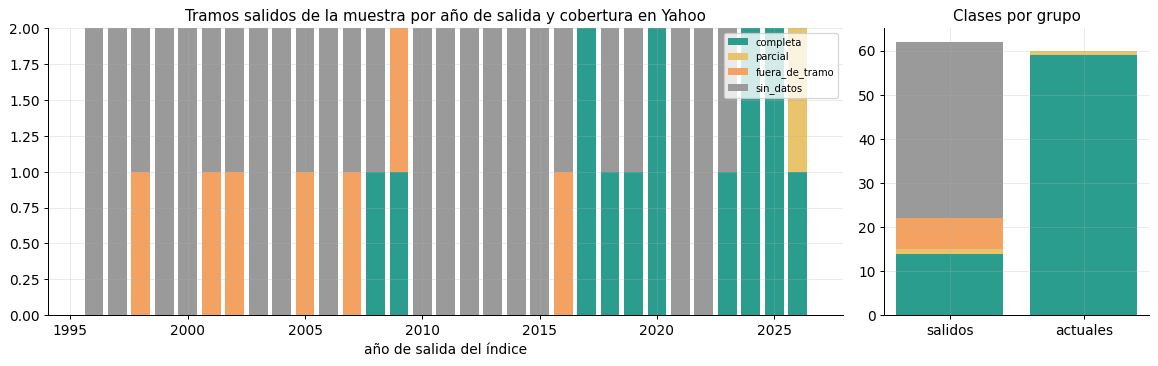

Salidos por clase: {'completa': 14, 'parcial': 1, 'fuera_de_tramo': 7, 'sin_datos': 40}
Actuales por clase: {'completa': 59, 'parcial': 1, 'fuera_de_tramo': 0, 'sin_datos': 0}


In [2]:
s = COB[COB['grupo'] == 'salido']
t = s.pivot_table(index='anio_salida', columns='clase', values='ticker', aggfunc='size', fill_value=0)
t = t.reindex(columns=list(sv.CLASES), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [3, 1]})
abajo = np.zeros(len(t))
for c in t.columns:
    axes[0].bar(t.index.astype(int), t[c], bottom=abajo, color=COLORES[c], label=c)
    abajo += t[c].to_numpy()
axes[0].set_title('Tramos salidos de la muestra por año de salida y cobertura en Yahoo')
axes[0].set_xlabel('año de salida del índice')
axes[0].legend(fontsize=8)
grupos = ('salido', 'actual')
izq = np.zeros(2)
for c in sv.CLASES:
    v = np.array([(COB[COB['grupo'] == g]['clase'] == c).sum() for g in grupos])
    axes[1].bar(['salidos', 'actuales'], v, bottom=izq, color=COLORES[c])
    izq += v
axes[1].set_title('Clases por grupo')
plt.tight_layout()
plt.show()
print('Salidos por clase:', MED['salidos_por_clase'])
print('Actuales por clase:', MED['actuales_por_clase'])

Por periodos de salida (metadatos: número de tramos, cuántos con precio completo y fracción media de sesiones
con precio):

In [3]:
pd.DataFrame(MED['salidos_por_periodo_de_salida']).T

,n,completa,fraccion_media
1996-2000,10.0,0.0,0.0
2001-2005,10.0,0.0,0.0
2006-2010,10.0,2.0,0.2
2011-2015,10.0,0.0,0.0
2016-2020,10.0,6.0,0.6
2021-2026,12.0,6.0,0.5


## 2. Fracción de sesiones con precio dentro del tramo

Cada punto es un tramo salido: año de salida frente a la fracción de sus sesiones en el índice que tienen precio. Las
salidas recientes son, a menudo, empresas que bajaron de tamaño y siguen cotizando (precio completo); las antiguas
acumulan compras, quiebras y tickers reutilizados.

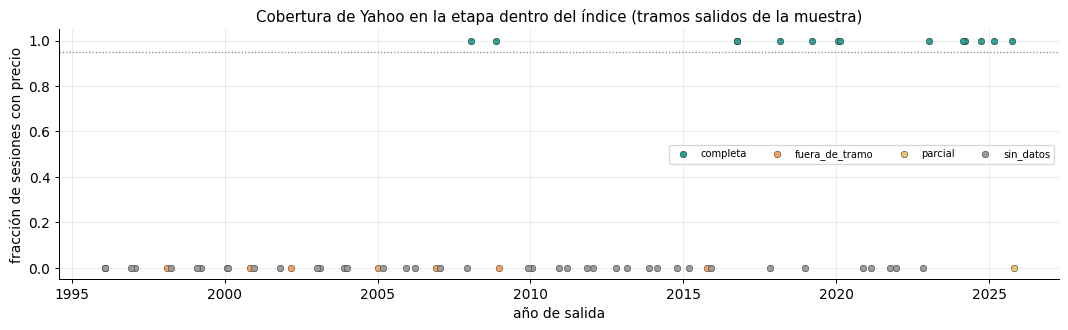

In [4]:
fig, ax = plt.subplots(figsize=(12, 3.8))
rng = np.random.default_rng(0)
for c, g in s.groupby('clase'):
    ax.scatter(g['anio_salida'].astype(int) + rng.uniform(-0.25, 0.25, len(g)), g['fraccion'],
               color=COLORES[c], label=c, s=28, edgecolor='k', lw=0.3)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel('fracción de sesiones con precio')
ax.set_xlabel('año de salida')
ax.axhline(sv.UMBRAL_COMPLETA, color='grey', ls=':', lw=1)
ax.legend(fontsize=8, ncol=4)
ax.set_title('Cobertura de Yahoo en la etapa dentro del índice (tramos salidos de la muestra)')
plt.tight_layout()
plt.show()

## 3. Sesgo: cartera point-in-time frente a supervivientes

- **PIT con precio**: cada mes, los miembros vigentes el primer día; la media de los salidos (muestra) y la de los
  actuales (muestra) se ponderan por cuántos miembros de cada grupo había ese mes. Solo entran los que tienen precio.
- **Supervivientes**: la muestra de miembros actuales, con todos sus meses con precio (la composición de hoy aplicada
  hacia atrás, el error típico de un backtest con la lista actual).

**Limitación declarada**: los salidos sin precio (quiebras, compras) no entran en la PIT y son los peores, así que la
diferencia medida es una **cota inferior** del sesgo. Además la muestra de salidos de cada mes es pequeña: la
diferencia mensual es ruidosa y la cifra útil es la media anualizada.

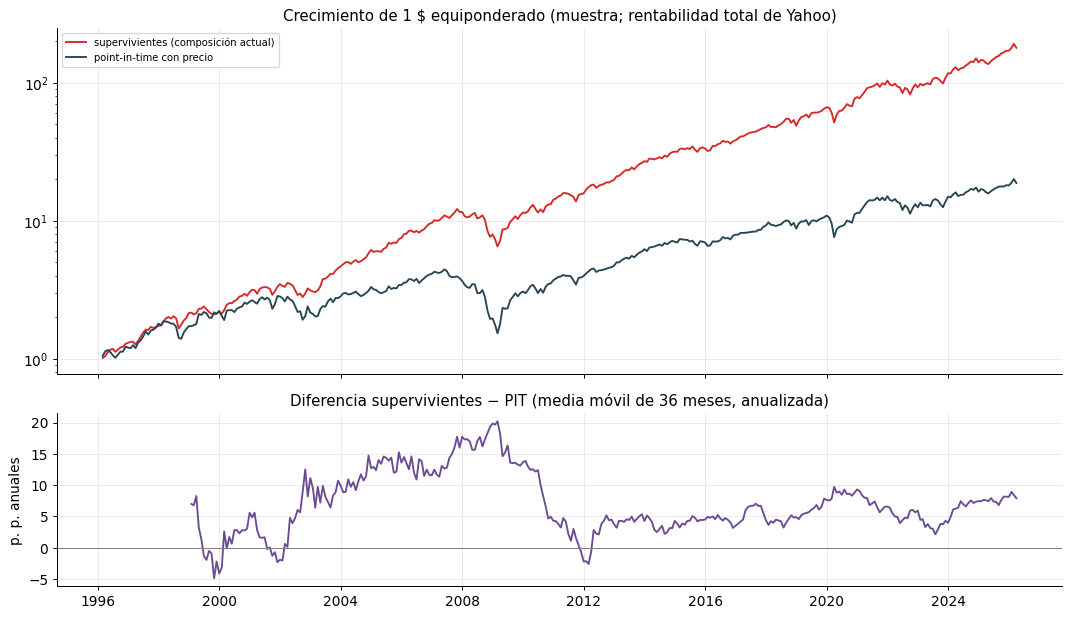

{'meses': 362, 'desde': '1996-02-29', 'hasta': '2026-03-31', 'pit_anual_pct': 11.7, 'supervivientes_anual_pct': 18.61, 'sesgo_anual_pct': 6.91, 'sesgo_t': 4.17}


In [5]:
S = SESGO.dropna(subset=['pit', 'supervivientes'])
S = S[~S['pit_solo_actuales']].set_index('mes')
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for col, color, nombre in (('supervivientes', '#d62828', 'supervivientes (composición actual)'),
                           ('pit', '#264653', 'point-in-time con precio')):
    axes[0].plot(S.index, (1 + S[col]).cumprod(), color=color, label=nombre)
axes[0].set_yscale('log')
axes[0].set_title('Crecimiento de 1 $ equiponderado (muestra; rentabilidad total de Yahoo)')
axes[0].legend(fontsize=8)
axes[1].plot(S.index, S['diferencia'].rolling(36).mean() * 1200, color='#6a4c93')
axes[1].axhline(0, color='grey', lw=0.8)
axes[1].set_ylabel('p. p. anuales')
axes[1].set_title('Diferencia supervivientes − PIT (media móvil de 36 meses, anualizada)')
axes[1].xaxis.set_major_locator(mdates.YearLocator(4))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()
print({k: v for k, v in MED['sesgo'].items() if k != 'limitacion'})

¿Cuántos miembros de la muestra tienen precio cada mes? Si no queda ningún salido con precio, la PIT de ese mes
se calcula solo con los actuales y no cuenta para el sesgo.

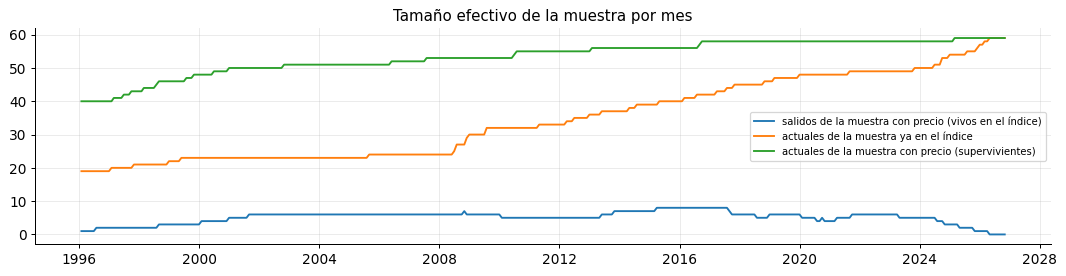

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.2))
M = SESGO.set_index('mes')
ax.plot(M.index, M['muestra_salidos_con_precio'], label='salidos de la muestra con precio (vivos en el índice)')
ax.plot(M.index, M['muestra_actuales_pit_con_precio'], label='actuales de la muestra ya en el índice')
ax.plot(M.index, M['muestra_supervivientes_con_precio'], label='actuales de la muestra con precio (supervivientes)')
ax.legend(fontsize=8)
ax.set_title('Tamaño efectivo de la muestra por mes')
plt.tight_layout()
plt.show()

## 4. Opciones de corrección

Ninguna fuente gratuita y sin cuenta da precios de deslistados. Decisión vigente: **WRDS/CRSP pendiente de MIAX**;
mientras tanto el sesgo se declara y se mide con esta cota. Alternativas documentadas en la ficha `supervivencia`:

In [7]:
for k, v in sv.OPCIONES_CORRECCION.items():
    print(f'- {k}: {v}')

- wrds_crsp: CRSP vía WRDS: precios y rentabilidades de deslistados (PERMNO, DLRET); pendiente de la licencia de MIAX. Es la corrección completa.
- alpha_vantage_listing_status: Alpha Vantage LISTING_STATUS (state=delisted): solo la LISTA de deslistados con fechas, sin precios. Sirve para identificar, no para corregir rentabilidades.
- tiingo: Tiingo EOD incluye muchos deslistados, pero exige una cuenta (y clave) del usuario; plan gratuito con límites diarios. No se ha probado aquí.
- imputacion_delisting: Sin precios: imputar la rentabilidad de salida (p. ej. -30 % en bajas por quiebra, Shumway 1997) solo como análisis de sensibilidad, declarado.


## Conclusiones

- La cobertura de los salidos depende del año de salida (sección 1): las salidas antiguas tienden a no tener precio o a
  tener el ticker ocupado por otra empresa; las recientes suelen seguir cotizando.
- La comparación de la sección 3 da la diferencia supervivientes − PIT con precio; como faltan justo los peores, el
  sesgo real es mayor que el medido.
- Para los agentes: los backtests de selección de acciones del S&P 500 con Yahoo **no** son válidos sin corrección; los
  de ETF e índices (el universo invertible del TFM) no tienen este problema. Las cifras están en la ficha
  `supervivencia`.